# 02 · Representaciones, descriptores y normalización

Con la unidad de análisis definida (700 segmentos distribuidora × clase), el
siguiente problema es **cómo describir la forma de una serie mensual** sin que el
tamaño del segmento domine el resultado.

Este notebook construye y compara las representaciones que después entran al
diseño de experimentos:

| Representación | Dimensión | Qué captura | Qué pierde |
|---|---|---|---|
| `serie68` | 68 | forma completa mes a mes | interpretabilidad directa |
| `estacional12` | 12 | patrón estacional promedio | evolución/tendencia |
| `descriptores` | 19 | tendencia, volatilidad, estacionalidad, drawdown | detalle temporal |
| `pca2/pca3_serie` | 2–3 | forma comprimida | varianza no explicada |
| `pca2/pca3_estacional` | 2–3 | estacionalidad comprimida | evolución |

In [1]:
import sys
from pathlib import Path

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)

from src import config as C

print("Raiz del proyecto:", RAIZ)
print("Ventana:", C.MES_INICIO, "a", C.MES_FIN, f"({C.N_MESES} meses)")

Raiz del proyecto: C:\Users\yennz\OneDrive\Documentos\Ciencia de Datos
Ventana: 2021-01 a 2026-08 (68 meses)


In [2]:
serie = pd.read_csv(C.PROCESSED_DIR / "matriz_serie68_mwh.csv", index_col=0)
estacional = pd.read_csv(C.PROCESSED_DIR / "matriz_estacional12_mwh.csv", index_col=0)
desc = pd.read_csv(C.PROCESSED_DIR / "descriptores.csv", index_col=0)
pca = pd.read_csv(C.PROCESSED_DIR / "pca_serie68.csv", index_col=0)
var = pd.read_csv(C.PROCESSED_DIR / "pca_varianza.csv")

pd.DataFrame({
    "representacion": ["serie68", "estacional12", "descriptores", "pca_serie68"],
    "filas": [serie.shape[0]] * 4,
    "columnas": [serie.shape[1], estacional.shape[1], len(__import__("src.aneel_pipeline", fromlist=["DESCRIPTORES_CLUSTER"]).DESCRIPTORES_CLUSTER), pca.shape[1]],
})

,representacion,filas,columnas
0,serie68,700,68
1,estacional12,700,12
2,descriptores,700,19
3,pca_serie68,700,10


## 1. El problema de escala

Tres segmentos pueden tener la misma *forma* (suben en verano, caen en invierno)
pero escalas muy distintas. Si se clusteriza la serie en MWh crudos, el algoritmo
separa por tamaño, no por comportamiento. La solución es normalizar **por fila**
(cada serie contra su propia media y desviación), de modo que todas las unidades
pesen igual y el clustering describa forma.

Unidades de ejemplo (representantes de cada arquetipo):
 - LIGHT SESA | Industrial
 - COOPERA | Residencial
 - CEGERO | Iluminação pública


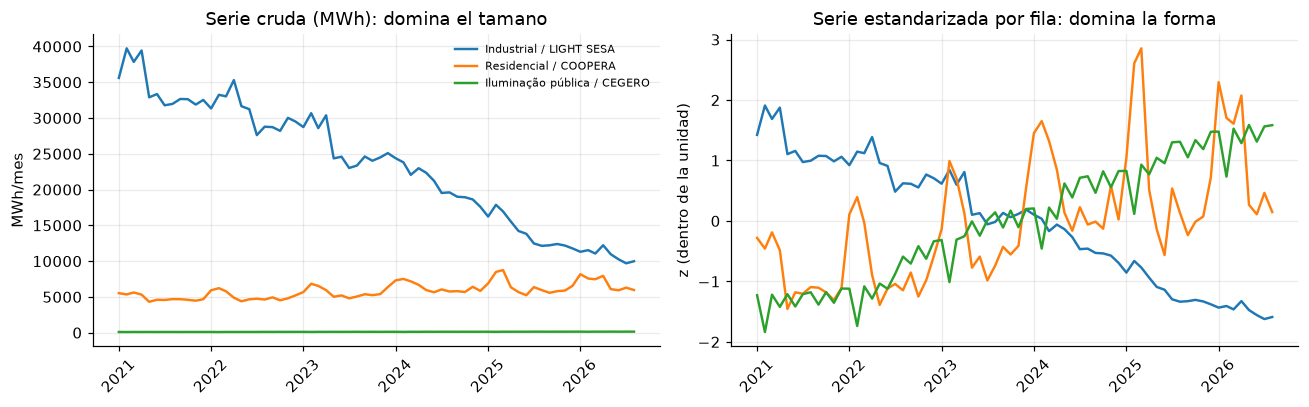

In [3]:
reps = pd.read_csv(C.TABLES_DIR / "final_representantes.csv")
unidades = reps.drop_duplicates("cluster")["unidad"].tolist()
print("Unidades de ejemplo (representantes de cada arquetipo):")
for u in unidades:
    print(" -", u)

x = pd.PeriodIndex(serie.columns, freq="M").to_timestamp()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for u in unidades:
    axes[0].plot(x, serie.loc[u].values, lw=1.6, label=u.split(" | ")[1] + " / " + u.split(" | ")[0][:12])
axes[0].set_title("Serie cruda (MWh): domina el tamano")
axes[0].set_ylabel("MWh/mes")

from src.aneel_pipeline import row_zscore
z = row_zscore(serie)
for u in unidades:
    axes[1].plot(x, z.loc[u].values, lw=1.6, label=u.split(" | ")[1])
axes[1].set_title("Serie estandarizada por fila: domina la forma")
axes[1].set_ylabel("z (dentro de la unidad)")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout()
plt.show()

## 2. Descriptores de forma

Cada serie se resume en 19 descriptores interpretables. No incluyen el nivel de
consumo (`total_mwh` se guarda aparte, solo para interpretar y para exponer
riesgo por distribuidora). Así el clustering no puede separar “grande” de
“pequeño”: solo “cómo se mueve”.

In [4]:
from src.aneel_pipeline import DESCRIPTORES_CLUSTER
tabla_desc = desc[DESCRIPTORES_CLUSTER].describe().T
tabla_desc["rango"] = tabla_desc["max"] - tabla_desc["min"]
tabla_desc[["mean", "std", "min", "50%", "max"]].round(3)

,mean,std,min,50%,max
cv,0.267,0.298,0.006,0.198,4.880
tendencia_pct_mes,-0.400,1.031,-4.601,-0.207,3.352
tendencia_r2,0.404,0.295,0.000,0.371,0.978
amplitud_estacional,0.352,0.417,0.008,0.271,6.789
fuerza_estacionalidad,0.277,0.239,0.005,0.191,0.982
ac1,0.714,0.253,-0.466,0.777,0.990
ac12,0.610,0.283,-0.413,0.692,0.976
yoy_media,0.011,0.345,-0.364,-0.008,6.834
yoy_std,0.402,2.358,0.007,0.133,50.773
drawdown_max,0.538,0.228,0.051,0.526,1.000


**Interpretación de los descriptores clave**

- `tendencia_pct_mes`: pendiente OLS como % de la media mensual. Es comparable
  entre segmentos de distinto tamaño.
- `crecimiento_12m`: promedio de los últimos 12 meses / promedio de los primeros
  12 − 1. Mide el cambio de régimen, no el ruido mensual.
- `drawdown_max`: mayor caída desde un máximo previo. Distingue una caída
  sostenida de una serie que solo oscila.
- `cv`, `amplitud_estacional`, `fuerza_estacionalidad`: volatilidad y estacionalidad.
- `ac1`, `ac12`: persistencia mensual y anual.
- `pico_sin/cos`, `valle_sin/cos`: codificación circular del mes de máximo/mínimo
  (evita que diciembre y enero queden “lejos”).

## 3. PCA: cuánta forma cabe en 2–3 dimensiones

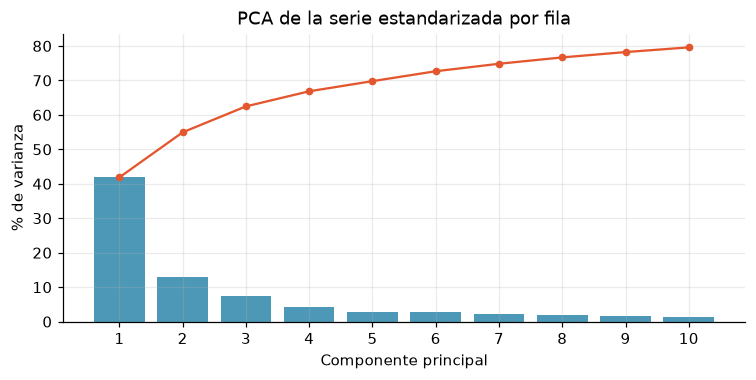

,componente,varianza_explicada,acumulada
0,PC1,0.4187,0.4187
1,PC2,0.1307,0.5494
2,PC3,0.0752,0.6247
3,PC4,0.0438,0.6685
4,PC5,0.0294,0.6979
5,PC6,0.0288,0.7267
6,PC7,0.0217,0.7484
7,PC8,0.0185,0.7668
8,PC9,0.0155,0.7823
9,PC10,0.0137,0.7960


In [5]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(range(1, len(var) + 1), var["varianza_explicada"] * 100, color="#2E86AB", alpha=0.85)
ax.plot(range(1, len(var) + 1), var["acumulada"] * 100, color="#E4572E", marker="o", ms=4, lw=1.5)
ax.set_xlabel("Componente principal")
ax.set_ylabel("% de varianza")
ax.set_title("PCA de la serie estandarizada por fila")
ax.set_xticks(range(1, len(var) + 1))
plt.show()
var.round(4)

PC1 y PC2 conservan solo una parte de la varianza. Por eso el PCA se usa como
**representación comparativa** dentro del DoE, no como única opción: si el
clustering en 2–3 dimensiones pierde estructura, el DoE lo va a mostrar con
peores métricas en el espacio de referencia común.

## 4. Invariancia a la escala

La siguiente tabla verifica que las normalizaciones por fila eliminan el nivel:
la media de cada fila queda en 0 y la desviación en 1 (o el rango en [0, 1]).

In [6]:
from src.aneel_pipeline import row_minmax, row_zscore

def winsor_fila(df, q=0.01):
    return df.clip(lower=df.quantile(q, axis=1), upper=df.quantile(1 - q, axis=1), axis=0)

def aplicar_escalado(df, nombre):
    if nombre == "z_fila":
        return row_zscore(df)
    if nombre == "minmax_fila":
        return row_minmax(df)
    if nombre == "winsor_z_fila":
        return row_zscore(winsor_fila(df))
    raise ValueError(nombre)

comparacion = pd.DataFrame({
    "crudo_media": serie.mean(axis=1),
    "crudo_std": serie.std(axis=1),
    "z_fila_media": aplicar_escalado(serie, "z_fila").mean(axis=1),
    "z_fila_std": aplicar_escalado(serie, "z_fila").std(axis=1),
    "minmax_fila_min": aplicar_escalado(serie, "minmax_fila").min(axis=1),
    "minmax_fila_max": aplicar_escalado(serie, "minmax_fila").max(axis=1),
}).head(5)
comparacion.round(3)

,crudo_media,crudo_std,z_fila_media,z_fila_std,minmax_fila_min,minmax_fila_max
unidad,,,,,,
CASTRO-DIS | Comercial,203.442,31.475,0.0,1.007,0.0,1.0
CASTRO-DIS | Iluminação pública,39.980,4.393,-0.0,1.007,0.0,1.0
CASTRO-DIS | Industrial,1217.044,781.834,0.0,1.007,0.0,1.0
CASTRO-DIS | Poder público,17.714,15.180,0.0,1.007,0.0,1.0
CASTRO-DIS | Residencial,277.030,59.201,0.0,1.007,0.0,1.0


## 5. Conclusión

- La unidad de análisis es el segmento distribuidora × clase (700 unidades).
- La serie de 68 meses es la representación más rica, pero exige normalizar por
  fila para que el tamaño no domine.
- Los descriptores ofrecen interpretabilidad y robustez; el PCA ofrece
  compacidad. Las tres compiten en igualdad de condiciones en el DoE.
- El nivel de consumo (`total_mwh`) se mantiene fuera del clustering y se usa
  después para ponderar el impacto económico de cada arquetipo.